# House Price Prediction: From Simple to Multiple Linear Regression

**Author:** Faith Njah

What drives a house's price? This notebook starts with a single feature (area) and adds features step by step, measuring how much each step improves predictions on houses the model has never seen.

**Dataset:** [Housing Prices Dataset (Kaggle)](https://www.kaggle.com/datasets/yasserh/housing-prices-dataset): 545 houses with price, area, rooms, stories, parking and amenities such as air conditioning and main-road access.

**Steps**
1. Load and explore the data
2. Prepare the features
3. Set up a fair evaluation
4. Model 1: simple linear regression (area only)
5. Model 2: multiple linear regression (area, bedrooms, bathrooms)
6. Model 3: full model (all 12 features)
7. Compare the models
8. Interpret the full model
9. Check the residuals
10. Predict, save and summarise

## 1. Load and explore the data

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv("../data/housing.csv")
print(f"{df.shape[0]} rows x {df.shape[1]} columns")
df.head()

545 rows x 13 columns


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", df.duplicated().sum())
df.info()

Missing values: 0
Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


| Column | Description | Type |
|---|---|---|
| price | Sale price (target) | Numerical |
| area | Plot area in square feet | Numerical |
| bedrooms, bathrooms, stories, parking | Counts | Numerical (discrete) |
| mainroad, guestroom, basement, hotwaterheating, airconditioning, prefarea | yes / no | Categorical (binary) |
| furnishingstatus | furnished / semi-furnished / unfurnished | Categorical (nominal) |

**Observation:** there are no missing values or duplicates. Seven columns are text and must be converted to numbers before a regression model can use them.

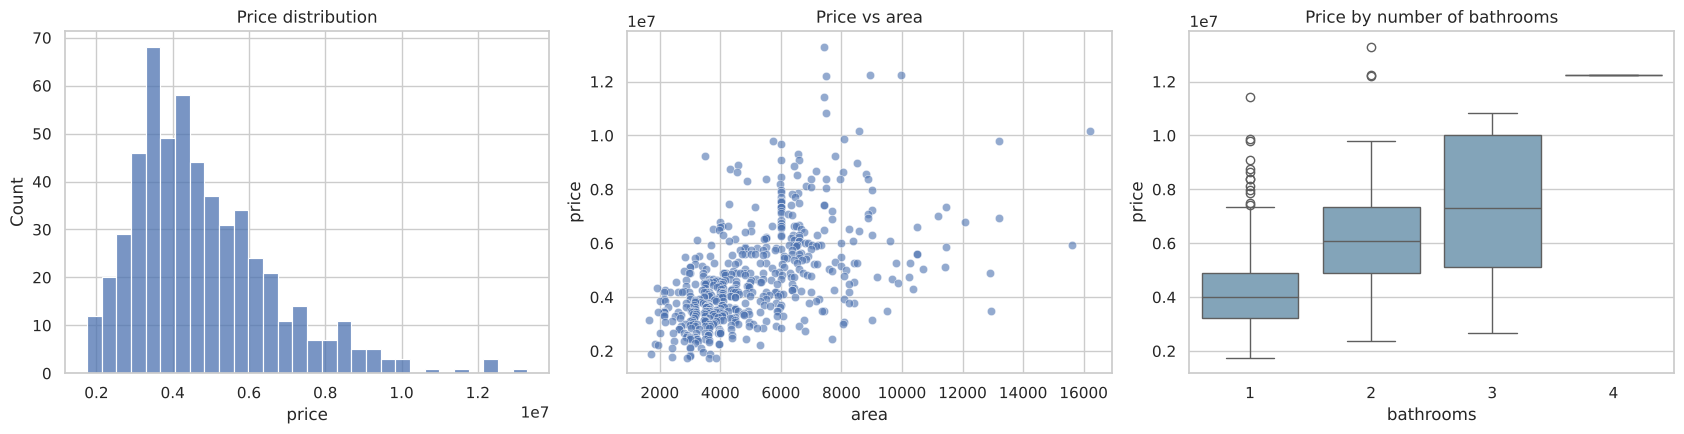

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df["price"], bins=30, ax=axes[0], color="#4c72b0")
axes[0].set_title("Price distribution")
sns.scatterplot(data=df, x="area", y="price", ax=axes[1], alpha=0.6, color="#4c72b0")
axes[1].set_title("Price vs area")
sns.boxplot(data=df, x="bathrooms", y="price", ax=axes[2], color="#7aa6c2")
axes[2].set_title("Price by number of bathrooms")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda.png", dpi=120)
plt.show()

**Observation:** prices are right-skewed (a few expensive houses), and price rises with area, though with a lot of scatter. Area alone clearly won't explain everything.

## 2. Prepare the features
- **Yes/no columns** → 1/0.
- **furnishingstatus** → one-hot encoding, because it has no natural order. "Furnished" is the baseline, so the model gets two columns, `semi-furnished` and `unfurnished`, each measured against a furnished house.

In [4]:
BINARY_COLS = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]

data = df.copy()
for col in BINARY_COLS:
    data[col] = data[col].map({"yes": 1, "no": 0})
data["furnishingstatus"] = pd.Categorical(
    data["furnishingstatus"], categories=["furnished", "semi-furnished", "unfurnished"])
data = pd.get_dummies(data, columns=["furnishingstatus"], drop_first=True, dtype=int)
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


## 3. Set up a fair evaluation
A model scored on the same houses it was trained on looks better than it really is. So:
- **20% of the houses are held out** as a test set that is used only for scoring;
- **5-fold cross-validation** gives a second, more stable estimate.

Each model is reported with R² (the share of price variation explained), MAE (the typical error) and RMSE (an error measure that penalises big misses more heavily).

In [5]:
train, test = train_test_split(data, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print(f"Training: {len(train)} houses | Test: {len(test)} houses")

results = []

def evaluate(name, cols):
    model = LinearRegression().fit(train[cols], train["price"])
    pred = model.predict(test[cols])
    row = {
        "model": name,
        "features": len(cols),
        "train R²": r2_score(train["price"], model.predict(train[cols])),
        "test R²": r2_score(test["price"], pred),
        "CV R²": cross_val_score(LinearRegression(), data[cols], data["price"], cv=cv).mean(),
        "test MAE": mean_absolute_error(test["price"], pred),
        "test RMSE": np.sqrt(mean_squared_error(test["price"], pred)),
    }
    results.append(row)
    return model, pred, row

Training: 436 houses | Test: 109 houses


## 4. Model 1: simple linear regression (area only)

Price = 2,512,254 + 426 x area
Test R²: 0.273 | Test MAE: 1,474,748


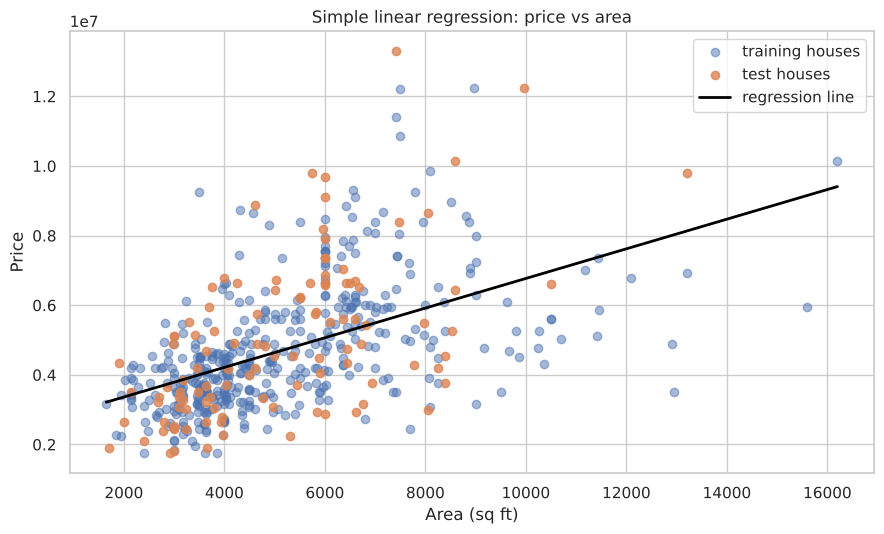

In [6]:
model_1, pred_1, row_1 = evaluate("Simple: area", ["area"])
print(f"Price = {model_1.intercept_:,.0f} + {model_1.coef_[0]:,.0f} x area")
print(f"Test R²: {row_1['test R²']:.3f} | Test MAE: {row_1['test MAE']:,.0f}")

x_line = pd.DataFrame({"area": np.linspace(data["area"].min(), data["area"].max(), 100)})
plt.figure(figsize=(9, 5.5))
plt.scatter(train["area"], train["price"], alpha=0.5, label="training houses", color="#4c72b0")
plt.scatter(test["area"], test["price"], alpha=0.8, label="test houses", color="#dd8452")
plt.plot(x_line["area"], model_1.predict(x_line), color="black", linewidth=2, label="regression line")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price")
plt.title("Simple linear regression: price vs area")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "simple_regression.png", dpi=120)
plt.show()

**Observation:** each extra square foot adds about 430 to the price, but area explains only about **27%** of the price variation in unseen houses. Houses of the same size sell for very different prices, so other features matter.

## 5. Model 2: multiple linear regression (area, bedrooms, bathrooms)

In [7]:
model_2, pred_2, row_2 = evaluate("Multiple: area, bedrooms, bathrooms", ["area", "bedrooms", "bathrooms"])
print(f"Test R²: {row_2['test R²']:.3f} | Test MAE: {row_2['test MAE']:,.0f}")

Test R²: 0.456 | Test MAE: 1,265,276


**Observation:** adding bedrooms and bathrooms raises the test R² to about **0.46**, a big step, and cuts the typical error by roughly 200,000.

## 6. Model 3: full model (all 12 features)
This adds stories, parking, every amenity and furnishing status.

In [8]:
FULL = ["area", "bedrooms", "bathrooms", "stories", "parking", *BINARY_COLS,
        "furnishingstatus_semi-furnished", "furnishingstatus_unfurnished"]
model_3, pred_3, row_3 = evaluate("Full: all 12 features", FULL)
print(f"Test R²: {row_3['test R²']:.3f} | Test MAE: {row_3['test MAE']:,.0f}")

Test R²: 0.653 | Test MAE: 970,043


## 7. Compare the models

In [9]:
comparison = pd.DataFrame(results).set_index("model")
comparison.style.format({"train R²": "{:.3f}", "test R²": "{:.3f}", "CV R²": "{:.3f}",
                         "test MAE": "{:,.0f}", "test RMSE": "{:,.0f}"})

,features,train R²,test R²,CV R²,test MAE,test RMSE
model,,,,,,
Simple: area,1,0.285,0.273,0.226,"1,474,748","1,917,104"
"Multiple: area, bedrooms, bathrooms",3,0.494,0.456,0.429,"1,265,276","1,658,325"
Full: all 12 features,13,0.686,0.653,0.632,"970,043","1,324,507"


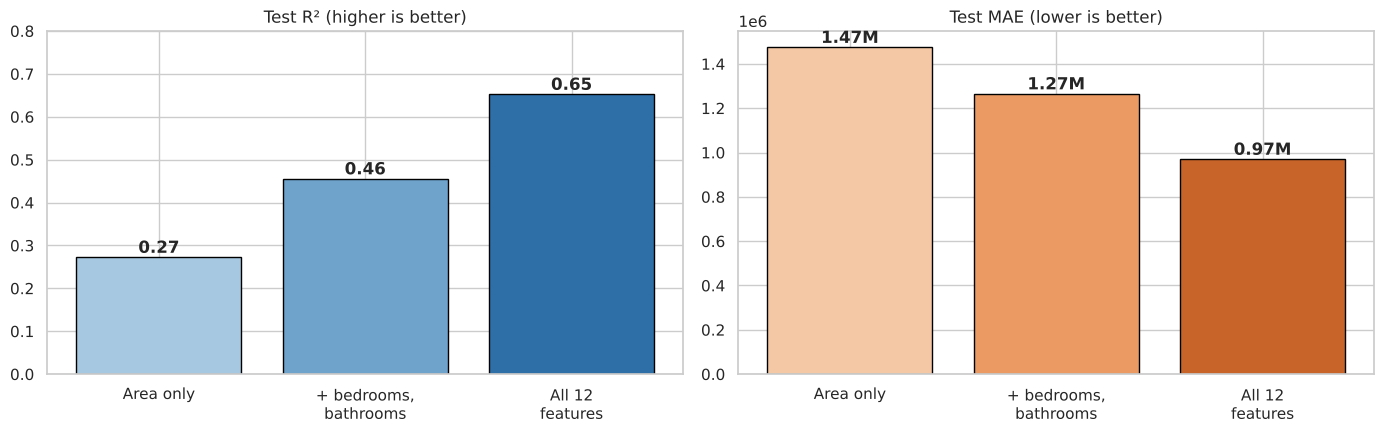

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
labels = ["Area only", "+ bedrooms,\nbathrooms", "All 12\nfeatures"]
axes[0].bar(labels, comparison["test R²"], color=["#a6c8e0", "#6fa3cc", "#2f6fa8"], edgecolor="black")
for i, v in enumerate(comparison["test R²"]):
    axes[0].text(i, v + 0.01, f"{v:.2f}", ha="center", fontweight="bold")
axes[0].set_ylim(0, 0.8)
axes[0].set_title("Test R² (higher is better)")
axes[1].bar(labels, comparison["test MAE"], color=["#f4c7a5", "#eb9a63", "#c8642a"], edgecolor="black")
for i, v in enumerate(comparison["test MAE"]):
    axes[1].text(i, v + 20000, f"{v/1e6:.2f}M", ha="center", fontweight="bold")
axes[1].set_title("Test MAE (lower is better)")
fig.tight_layout()
fig.savefig(FIG_DIR / "model_comparison.png", dpi=120)
plt.show()

**Observation:** each model beats the one before it. The full model explains about **65%** of the price variation in unseen houses (up from 27% with area alone), and its typical error falls from about 1.47M to 0.97M. Train and test scores stay close for every model, so none of them is overfitting.

## 8. Interpret the full model
Each coefficient is the change in price for a one-unit increase in that feature, **holding all other features constant**.

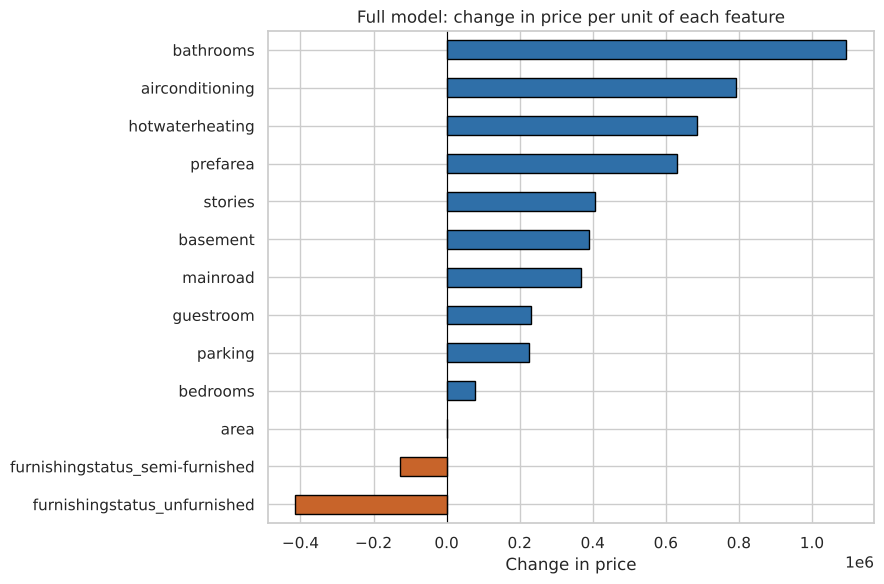

,coefficient
bathrooms,1094445.0
airconditioning,791427.0
hotwaterheating,684650.0
prefarea,629891.0
stories,407477.0
basement,390251.0
mainroad,367920.0
guestroom,231610.0
parking,224842.0
bedrooms,76779.0


In [11]:
coefs = pd.Series(model_3.coef_, index=FULL).sort_values()
plt.figure(figsize=(9, 6))
colors = ["#c8642a" if c < 0 else "#2f6fa8" for c in coefs]
coefs.plot.barh(color=colors, edgecolor="black")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Full model: change in price per unit of each feature")
plt.xlabel("Change in price")
plt.tight_layout()
plt.savefig(FIG_DIR / "coefficients.png", dpi=120)
plt.show()
coefs.sort_values(ascending=False).round(0).to_frame("coefficient")

**What adds the most value** (all else equal):
- **Each extra bathroom:** about +1.09M
- **Air conditioning:** about +790,000
- **Hot water heating:** about +680,000
- **Preferred area:** about +630,000
- **Each extra story:** about +410,000

**What lowers value:** being **unfurnished** costs about 410,000 compared with a furnished house.

**Bedrooms** add only about 77,000 once bathrooms and area are accounted for, because larger houses tend to have both. Bathrooms carry most of that information. Each square foot of area adds about 236, less than in the simple model, because some of the value area seemed to explain on its own actually comes from the amenities that bigger houses tend to have.

## 9. Check the residuals

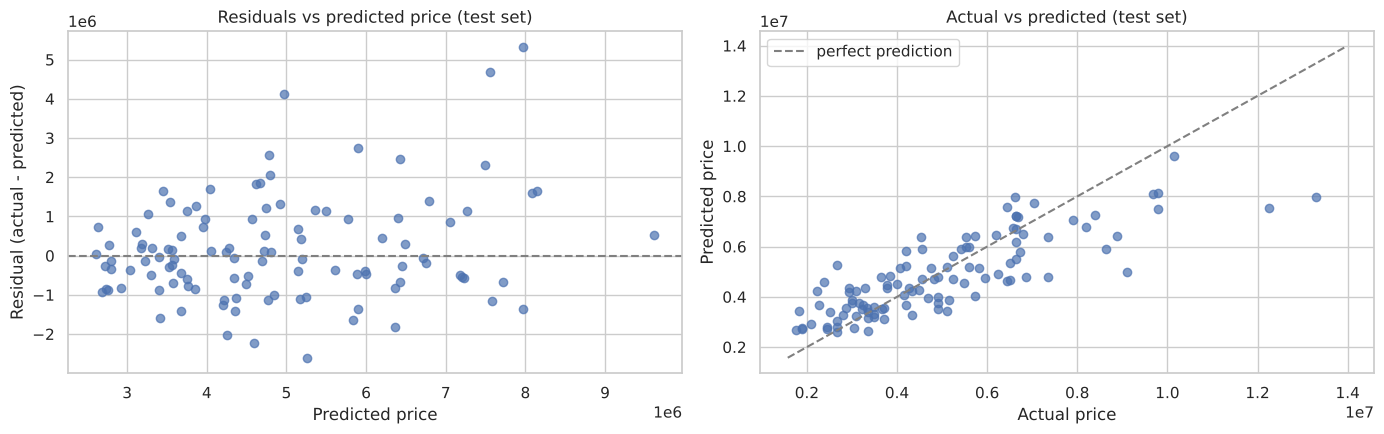

In [12]:
residuals = test["price"] - pred_3
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(pred_3, residuals, alpha=0.7, color="#4c72b0")
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_xlabel("Predicted price")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs predicted price (test set)")
lims = [test["price"].min() * 0.9, test["price"].max() * 1.05]
axes[1].scatter(test["price"], pred_3, alpha=0.7, color="#4c72b0")
axes[1].plot(lims, lims, "--", color="gray", label="perfect prediction")
axes[1].set_xlabel("Actual price")
axes[1].set_ylabel("Predicted price")
axes[1].set_title("Actual vs predicted (test set)")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "residuals.png", dpi=120)
plt.show()

**Observation:** for typical houses the errors scatter around zero, but they **grow for expensive houses**, and the most expensive ones tend to be under-predicted. This is a known limit of a plain linear model on skewed prices. Modelling log(price), or a non-linear model, would be a natural next step.

## 10. Predict, save and summarise

In [13]:
final_model = LinearRegression().fit(data[FULL], data["price"])

example = pd.DataFrame([{
    "area": 6000, "bedrooms": 3, "bathrooms": 2, "stories": 2, "parking": 1,
    "mainroad": 1, "guestroom": 0, "basement": 0, "hotwaterheating": 0,
    "airconditioning": 1, "prefarea": 0,
    "furnishingstatus_semi-furnished": 1, "furnishingstatus_unfurnished": 0,
}])[FULL]
print(f"Predicted price for the example house: {final_model.predict(example)[0]:,.0f}")

Path("../models").mkdir(exist_ok=True)
joblib.dump(final_model, "../models/house_price_model.joblib")
print("Model saved to models/house_price_model.joblib")

Predicted price for the example house: 6,245,996
Model saved to models/house_price_model.joblib


### Summary

| Model | Features | Test R² | Test MAE |
|---|---|---|---|
| Simple | area | ≈ 0.27 | ≈ 1.47M |
| Multiple | area, bedrooms, bathrooms | ≈ 0.46 | ≈ 1.27M |
| Full | all 12 | ≈ 0.65 | ≈ 0.97M |

- Area alone is a weak predictor. Rooms, amenities and location together explain much more.
- Bathrooms, air conditioning, hot water heating and a preferred area add the most value.
- The model is weakest on expensive houses, which points to log-transforming the price or trying non-linear models next.